In [41]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_squared_error, r2_score

In [42]:
df=pd.read_csv('uber.csv')
df.head()
df.info()


<class 'pandas.DataFrame'>
RangeIndex: 200000 entries, 0 to 199999
Data columns (total 9 columns):
 #   Column             Non-Null Count   Dtype  
---  ------             --------------   -----  
 0   Unnamed: 0         200000 non-null  int64  
 1   key                200000 non-null  str    
 2   fare_amount        200000 non-null  float64
 3   pickup_datetime    200000 non-null  str    
 4   pickup_longitude   200000 non-null  float64
 5   pickup_latitude    200000 non-null  float64
 6   dropoff_longitude  199999 non-null  float64
 7   dropoff_latitude   199999 non-null  float64
 8   passenger_count    200000 non-null  int64  
dtypes: float64(5), int64(2), str(2)
memory usage: 13.7 MB


In [43]:

df.isnull().sum()
df.dropna()

,Unnamed: 0,key,fare_amount,pickup_datetime,pickup_longitude,pickup_latitude,dropoff_longitude,dropoff_latitude,passenger_count
0,24238194,2015-05-07 19:52:06.0000003,7.5,2015-05-07 19:52:06 UTC,-73.999817,40.738354,-73.999512,40.723217,1
1,27835199,2009-07-17 20:04:56.0000002,7.7,2009-07-17 20:04:56 UTC,-73.994355,40.728225,-73.994710,40.750325,1
2,44984355,2009-08-24 21:45:00.00000061,12.9,2009-08-24 21:45:00 UTC,-74.005043,40.740770,-73.962565,40.772647,1
3,25894730,2009-06-26 08:22:21.0000001,5.3,2009-06-26 08:22:21 UTC,-73.976124,40.790844,-73.965316,40.803349,3
4,17610152,2014-08-28 17:47:00.000000188,16.0,2014-08-28 17:47:00 UTC,-73.925023,40.744085,-73.973082,40.761247,5
...,...,...,...,...,...,...,...,...,...
199995,42598914,2012-10-28 10:49:00.00000053,3.0,2012-10-28 10:49:00 UTC,-73.987042,40.739367,-73.986525,40.740297,1
199996,16382965,2014-03-14 01:09:00.0000008,7.5,2014-03-14 01:09:00 UTC,-73.984722,40.736837,-74.006672,40.739620,1
199997,27804658,2009-06-29 00:42:00.00000078,30.9,2009-06-29 00:42:00 UTC,-73.986017,40.756487,-73.858957,40.692588,2
199998,20259894,2015-05-20 14:56:25.0000004,14.5,2015-05-20 14:56:25 UTC,-73.997124,40.725452,-73.983215,40.695415,1


In [44]:
df['distance'] = ((df['pickup_longitude']-df['dropoff_longitude'])**2 + (df['pickup_latitude']-df['dropoff_latitude'])**2 ) * 0.5

In [45]:
df = df[(df['fare_amount'] >0 ) & ( df['fare_amount'] <100 ) ] 

In [46]:
df=df[  (df['passenger_count'] >0) & (df['passenger_count']) <6 ]
df= df[df['distance'] <5]


In [49]:
df['pickup_datetime'] = pd.to_datetime(df['pickup_datetime'])
df['hour'] = df['pickup_datetime'].dt.hour
df['day_of_week'] =df['pickup_datetime'].dt.day_of_week 

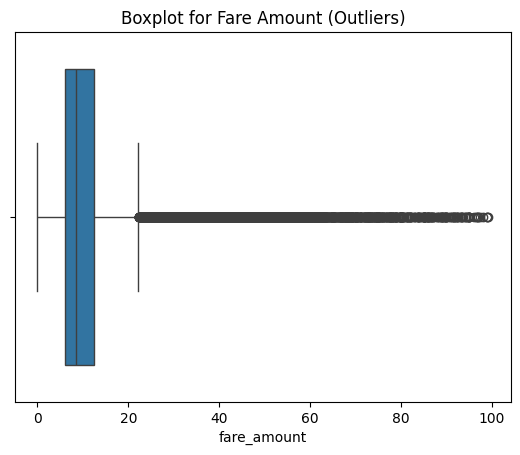

In [55]:
sns.boxplot(x= df['fare_amount'])
plt.title("Boxplot for Fare Amount (Outliers)")
plt.show()

In [57]:
corr=df[ ['fare_amount', 'distance','passenger_count','hour', 'day_of_week' ] ].corr()

<Axes: >

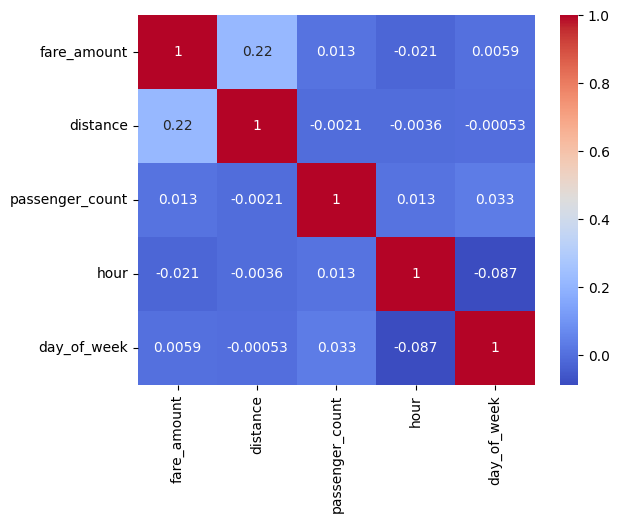

In [60]:
sns.heatmap(corr,annot=True, cmap="coolwarm")

In [64]:
x=df[ [ 'distance','passenger_count','hour', 'day_of_week' ]]
y=df['fare_amount']

x_train, x_test, y_train, y_test=train_test_split(x,y, test_size=0.2 , random_state=42 )

In [65]:
lr=LinearRegression()
lr.fit(x_train,y_train )
y_pred_lr=lr.predict(x_test);

In [68]:
rf=RandomForestRegressor(n_estimators=100 , random_state=42)
rf.fit(x_train,y_train )
y_pred_rf=rf.predict(x_test)

In [73]:

def evaluate(y_true, y_pred, model_name):
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))
    r2 = r2_score(y_true, y_pred)
    print(f"{model_name} Results:")
    print(f"  R² Score: {r2:.4f}")
    print(f"  RMSE: {rmse:.4f}\n")

In [74]:
evaluate(y_test, y_pred_lr, "Linear Regression")
evaluate(y_test, y_pred_rf, "Random Forest Regression")

Linear Regression Results:
  R² Score: 0.0565
  RMSE: 9.1048

Random Forest Regression Results:
  R² Score: 0.7509
  RMSE: 4.6779

